# 03 · Post-training quantization (PTQ) of a small CNN

First real network. We train a float model once, then quantize it **without any training** (PTQ) using the level
families of notebook 02, and look at accuracy, size and the save/load path.

| Step | What you will see |
|---|---|
| 1 | data and the float baseline (the SmallResNet of the v0.x notebooks) |
| 2 | wrap the model: `VVTK_QModel`, which layers get quantized |
| 3 | PTQ accuracy vs bits for uniform / equal-probability / Lloyd-Max / FP4 |
| 3b | the v0.x equal-probability calibrations (`v=0`, `v=1`) against the new `eqprob` |
| 4 | does lower weight MSE mean higher accuracy? |
| 5 | save as packed indices, load, check it is bit-exact |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

> 📘 Everything in this notebook is **common practice** (PTQ, per-tensor levels, evaluating the hard model, packed
> storage). Read: Nagel et al. white paper (arXiv:2106.08295) §3 on PTQ. The only vvtk_quant-specific choices are the
> level families of notebook 02.

Helpers (data, model, train loop) live in `common_cifar.py` next to this notebook: open it, it is short.

In [1]:
import os, sys, copy
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from vvtk_quant import VVTK_QModel, mse
from common_cifar import DEVICE, OUT, loaders, SmallResNet, evaluate, pretrained_fp32
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("device:", DEVICE)

device: cuda


## Step 1 · Float baseline
5 epochs of Adam, as in the original notebooks (the checkpoint is cached in `out/`, so this runs once).

In [2]:
train_loader, test_loader = loaders()
fp32 = pretrained_fp32(train_loader, test_loader, epochs=5)
acc_fp32 = evaluate(fp32, test_loader)
n_params = sum(p.numel() for p in fp32.parameters())
print(f"fp32 test accuracy: {acc_fp32:.2f}%   parameters: {n_params / 1e6:.2f} M")

fp32 epoch 1/5  loss 1.559  test acc 52.54%  (29s)
fp32 epoch 2/5  loss 1.141  test acc 53.06%  (4s)
fp32 epoch 3/5  loss 0.982  test acc 65.38%  (4s)
fp32 epoch 4/5  loss 0.847  test acc 71.99%  (4s)
fp32 epoch 5/5  loss 0.759  test acc 68.68%  (4s)
fp32 test accuracy: 68.68%   parameters: 4.83 M


## Step 2 · Wrapping the model

`VVTK_QModel(model, b, module_types)` finds every layer of the given types; `calibrate_quant(method=...)` computes the
levels **per tensor** from the trained weights and swaps each layer for its quantized version (`QConv2d`, `QLinear`).

In `eval()` mode a quantized layer always uses the **hard** staircase, so what we measure is the deployed model.
BatchNorm and biases of BN stay in float (they can be folded into the previous conv: `fuse_conv_bn=True`).

In [3]:
q = VVTK_QModel(copy.deepcopy(fp32), b=4, module_types=[nn.Conv2d, nn.Linear], verbose=True)
q.calibrate_quant(method="lloyd")
print(q.model.layer1)

Quantization keys: ['conv1.weight', 'layer1.conv1.weight', 'layer1.conv2.weight', 'layer1.shortcut.0.weight', 'layer2.conv1.weight', 'layer2.conv2.weight', 'layer2.shortcut.0.weight', 'layer3.conv1.weight', 'layer3.conv2.weight', 'layer3.shortcut.0.weight', 'fc.weight', 'fc.bias']
Levels calibrated (lloyd), up to 16 levels, 4 bits, 12 tensors.
Replacing conv1 with QConv2d
Replacing layer1.conv1 with QConv2d
Replacing layer1.conv2 with QConv2d
Replacing layer1.shortcut.0 with QConv2d
Replacing layer2.conv1 with QConv2d
Replacing layer2.conv2 with QConv2d
Replacing layer2.shortcut.0 with QConv2d
Replacing layer3.conv1 with QConv2d
Replacing layer3.conv2 with QConv2d
Replacing layer3.shortcut.0 with QConv2d
Replacing fc with QLinear
ResidualBlock(
  (conv1): QConv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False, L=16, mode=soft, T=10, lam=0)
  (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): QConv2d(128, 128, kerne

## Step 3 · PTQ accuracy vs bits

For each family and bit width: copy the float model, calibrate, evaluate. No training at all.

 uniform: 8b 69.33%  6b 68.94%  4b 66.87%  3b 36.17%  2b 10.00%


  eqprob: 8b 69.01%  6b 66.96%  4b 57.82%  3b 42.13%  2b 18.60%


   lloyd: 8b 69.32%  6b 68.28%  4b 65.43%  3b 57.93%  2b 33.10%


fp4 e2m1 (4 bits, per-tensor scale): 63.09%


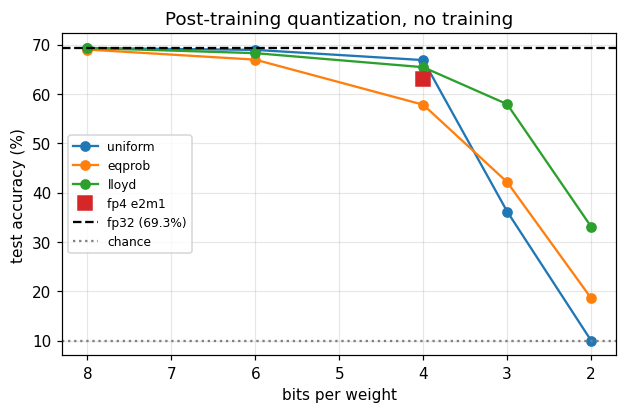

In [4]:
def ptq(method, b, **kw):
    q = VVTK_QModel(copy.deepcopy(fp32), b=b, module_types=[nn.Conv2d, nn.Linear])
    q.calibrate_quant(method=method, **kw)
    return evaluate(q, test_loader), q

bits = [8, 6, 4, 3, 2]
results = {}
for method in ["uniform", "eqprob", "lloyd"]:
    results[method] = [ptq(method, b)[0] for b in bits]
    print(f"{method:>8}: " + "  ".join(f"{b}b {a:5.2f}%" for b, a in zip(bits, results[method])))
acc_fp4 = ptq("fp", 4, e=2, m=1)[0]
print(f"fp4 e2m1 (4 bits, per-tensor scale): {acc_fp4:.2f}%")

plt.figure(figsize=(6.5, 3.8))
for method, accs in results.items():
    plt.plot(bits, accs, "o-", label=method)
plt.plot([4], [acc_fp4], "s", ms=9, label="fp4 e2m1")
plt.axhline(acc_fp32, color="k", ls="--", label=f"fp32 ({acc_fp32:.1f}%)")
plt.axhline(10, color="gray", ls=":", label="chance")
plt.gca().invert_xaxis(); plt.xlabel("bits per weight"); plt.ylabel("test accuracy (%)")
plt.title("Post-training quantization, no training"); plt.legend(fontsize=8); plt.show()

## Step 3b · The v0.x equal-probability calibrations against the new levels

The functions of v0.x are still in the library: `calibrate_quant(v=0)` builds **one** table from the histogram of all
the weights together, and `calibrate_quant(v=1)` builds one table per tensor. Both take the upper edge of each bin of
mass as the level. The new `eqprob` takes exact quantiles at the centre of each bin of mass (see Step 3b of
notebook 02). Here all of them quantize the same float model, so the differences in accuracy come only from the levels.

method                             |     8b |     6b |     4b |     3b |     2b
v0 (shared, hist, upper)           |  24.95 |  16.70 |  17.67 |  12.93 |  10.16
v1 (per tensor, hist, upper)       |  69.04 |  67.89 |  47.89 |  20.46 |  10.08
eqprob mid=False (exact, upper)    |  68.81 |  67.80 |  48.20 |  20.55 |  10.08
eqprob mid=True (exact, centre)    |  69.01 |  66.96 |  57.82 |  42.13 |  18.60
lloyd                              |  69.32 |  68.28 |  65.43 |  57.93 |  33.10
uniform                            |  69.33 |  68.94 |  66.87 |  36.17 |  10.00


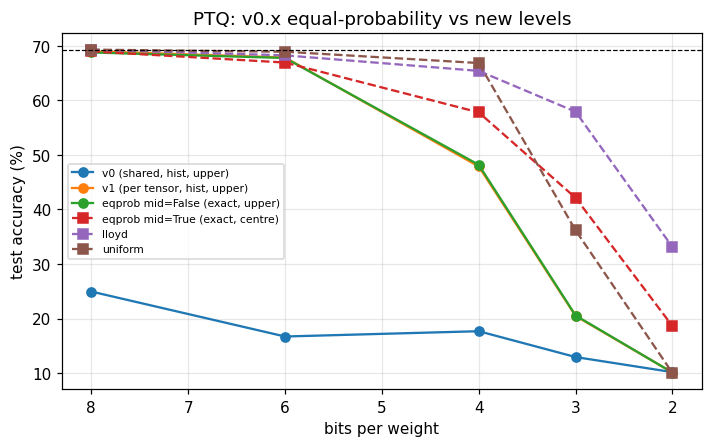

In [5]:
def ptq_v(v, b):
    q = VVTK_QModel(copy.deepcopy(fp32), b=b, module_types=[nn.Conv2d, nn.Linear])
    q.calibrate_quant(v=v)
    return evaluate(q, test_loader), q

old = {"v0 (shared, hist, upper)": [ptq_v(0, b)[0] for b in bits],
       "v1 (per tensor, hist, upper)": [ptq_v(1, b)[0] for b in bits],
       "eqprob mid=False (exact, upper)": [ptq("eqprob", b, mid=False)[0] for b in bits]}
allres = {**old,
          "eqprob mid=True (exact, centre)": results["eqprob"],
          "lloyd": results["lloyd"],
          "uniform": results["uniform"]}

print(f"{'method':<34} | " + " | ".join(f"{b}b".rjust(6) for b in bits))
for name, accs in allres.items():
    print(f"{name:<34} | " + " | ".join(f"{a:6.2f}" for a in accs))

plt.figure(figsize=(7.5, 4.2))
for name, accs in allres.items():
    plt.plot(bits, accs, "o-" if name in old else "s--", label=name)
plt.axhline(acc_fp32, color="k", ls="--", lw=0.8)
plt.gca().invert_xaxis(); plt.xlabel("bits per weight"); plt.ylabel("test accuracy (%)")
plt.title("PTQ: v0.x equal-probability vs new levels"); plt.legend(fontsize=7); plt.show()

### Reading the results of Step 3b (one run, one seed)

* **A shared table is a disaster on a real network.** `v0` gives 25.0 % at 8 bits, where `v1` gives 69.0 % and the float
  model gives 69.3 %. At 4 bits `v0` has 17.7 %. The layers have very different scales, so a table built from all the
  weights together does not fit most of them. (The average relative MSE of notebook 02 hid this.)
* **The histogram of v0.x costs nothing again.** `v1` and `eqprob(mid=False)` are within 0.4 points at 8, 6 and 4 bits,
  and equal at 3 and 2 bits. With 256 levels and only 512 bins (8 bits) there is no visible loss.
* **The centre of the bin matters at 4 bits and below.** From `mid=False` to `mid=True` accuracy rises from 48.2 % to
  57.8 % at 4 bits, from 20.6 % to 42.1 % at 3 bits, and from 10.1 % to 18.6 % at 2 bits. At 6 bits it falls from 67.8 %
  to 67.0 %, at 8 bits it rises from 68.8 % to 69.0 %. Both are small, and I did not repeat the run, so I would not
  read them as real.
* **The order at 4 bits still holds with the old variants added:** uniform 66.9 % > Lloyd 65.4 % > `eqprob` 57.8 % >
  `v1` 47.9 % > `v0` 17.7 %. At 3 and 2 bits Lloyd is first.

## Step 4 · Does lower weight MSE mean higher accuracy?

Lloyd-Max minimises the weight MSE by construction. But the network does not care about weight error directly; it
cares about the error in its **outputs**. A quick check: for every (method, bits) point, the average relative MSE of
the weights, $\overline{D/\mathbb{E}[w^2]}$, against the accuracy.

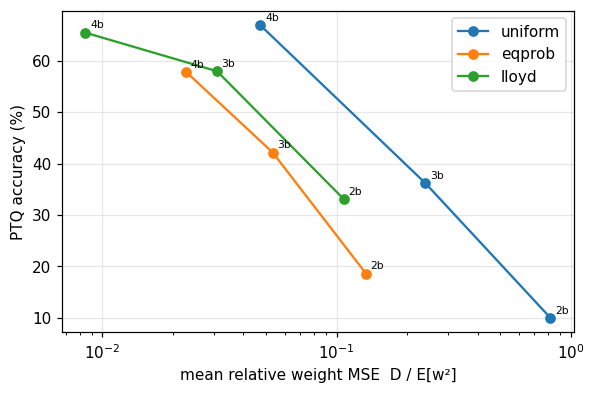

In [6]:
pts = []
for method in ["uniform", "eqprob", "lloyd"]:
    for b in [4, 3, 2]:
        acc, qm = ptq(method, b)
        sd = fp32.state_dict()
        rel = np.mean([mse(sd[k], qm.edge_dict[k]) / float((sd[k] ** 2).mean()) for k in qm.qkeys])
        pts.append((method, b, rel, acc))
plt.figure(figsize=(6, 3.8))
for method, c in zip(["uniform", "eqprob", "lloyd"], ["C0", "C1", "C2"]):
    P = [p for p in pts if p[0] == method]
    plt.semilogx([p[2] for p in P], [p[3] for p in P], "o-", color=c, label=method)
    for p in P: plt.annotate(f"{p[1]}b", (p[2], p[3]), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.xlabel("mean relative weight MSE  D / E[w²]"); plt.ylabel("PTQ accuracy (%)"); plt.legend(); plt.show()

Mostly monotone, but not exactly: two quantizers with similar weight MSE can give different accuracy. Weight MSE is a
proxy. QAT (next notebook) optimizes the real objective.

## Step 5 · Save, load, size

`apply_quant()` writes the hard levels into the weights and stores the level **indices**; `save()` packs them with
$b$ bits each (plus the small level tables and the float BatchNorm parameters) in a gzipped pickle.

In [7]:
acc4, q4 = ptq("lloyd", 4)
q4.apply_quant()
path = os.path.join(OUT, "cifar_lloyd_4b_ptq.q.gz")
q4.save(path)
torch.save(fp32.state_dict(), os.path.join(OUT, "fp32_copy.pth"))

q_loaded = VVTK_QModel(SmallResNet().to(DEVICE), module_types=[nn.Conv2d, nn.Linear])
q_loaded.load(path)
acc_loaded = evaluate(q_loaded, test_loader)

print("\n" + "=" * 72)
print(f"{'model':<28} | {'accuracy':>9} | {'file size (MB)':>14}")
print("-" * 72)
print(f"{'fp32 (torch.save)':<28} | {acc_fp32:8.2f}% | {os.path.getsize(os.path.join(OUT, 'fp32_copy.pth')) / 1e6:14.2f}")
print(f"{'lloyd 4-bit PTQ (in memory)':<28} | {acc4:8.2f}% | {'':>14}")
print(f"{'lloyd 4-bit PTQ (loaded)':<28} | {acc_loaded:8.2f}% | {os.path.getsize(path) / 1e6:14.2f}")
print("=" * 72)
assert abs(acc_loaded - acc4) < 1e-9, "save/load must be exact"


model                        |  accuracy | file size (MB)
------------------------------------------------------------------------
fp32 (torch.save)            |    69.28% |          19.36
lloyd 4-bit PTQ (in memory)  |    65.43% |               
lloyd 4-bit PTQ (loaded)     |    65.43% |           2.21


### Reading the results (v1.0 run, one seed; numbers in the cells above)

* The float model is **under-trained** (5 epochs: 69.3 %; notebook 04 shows it reaches 81 % with 3 more epochs). This
  is the v0.x setup, kept for continuity; a better-trained baseline is exercise 4 of notebook 04. The test accuracy
  moves up and down between epochs, so differences of about one point between methods are within the noise.
* At 2–3 bits the ranking is the expected one: Lloyd-Max (57.9 % at 3 bits, 33.1 % at 2 bits) > equal-probability
  (42.1 / 18.6) > uniform (36.2 / 10.0, which is chance level at 2 bits).
* **At 4 bits the ranking flips: uniform 66.9 % > Lloyd 65.4 % > equal-probability 57.8 %**, although Lloyd has the
  lowest weight MSE. Weight MSE is a proxy: the network cares about the error on its outputs, and on a few large weights
  that the non-uniform grids represent coarsely. Step 4 shows this; the exercise 3 (output MSE) is the way to dig in.
* FP4 E2M1 with a per-tensor scale: 63.1 % at 4 bits (the v0.x unscaled table gave 10 %).
* The v0.x calibrations (Step 3b) are worse than the new `eqprob` at 4 bits and below, and the shared table of `v=0`
  fails at every bit width.

### Take-aways
* At 8 and 6 bits every family is close to float without any training. At 4 bits and below the level placement matters
  (read the figure), and at 2–3 bits PTQ alone is not enough: we need QAT.
* The saved model is ~8x smaller than fp32 at 4 bits, and loading is exact (the assert above).

### Exercises
1. Quantize only the convolutions (`module_types=[nn.Conv2d]`). Which layer types hurt most at 3 bits?
2. Try `fuse_conv_bn=True` (BatchNorm folded into the conv before quantizing). Better or worse at 4 bits? Why?
3. Measure the **output** MSE (logits of fp32 vs quantized) instead of weight MSE in Step 4. Is it a better predictor?

**Next:** [04 · QAT: soft staircase vs STE](04_qat_soft_vs_ste.ipynb).